# When "Free" Is Not Spam: TF-IDF vs. Sentence Embeddings on Spam-Like Legitimate SMS
**NLP Project — Option 1: Spam Detection** · Section 7MA2 · Group 7 · Dr. Mohammed Talal Ahmed Mousalli

| Name | ID | Role |
|---|---|---|
| Faisal Abdullah Ali Al Shehri | 2240001737 | Team Leader |
| Saad Abdulaziz Saad Al Shehri | 2240006495 | Member 2 |
| Nawaf Rabie Hassan bin Shahbal | 2240009025 | Member 3 |

**Experimental question:** Which method better avoids false spam alerts on legitimate messages that contain spam-associated words such as "free", "win" or "call"?

**Environment:** Google Colab. Run with *Runtime → Restart and run all*.

Sections: 1 Setup · 2 Data · 3 Method 1 · 4 Method 2 · 5 Results · 6 Try it · 7 Sources

## 1. Setup

In [1]:
# Clone the repository when running in Colab, then work from the repo root (relative paths).
import os, sys
REPO_URL = "https://github.com/FaisalAlshehri-1/Group7_NLP_Spam_Detection.git"
REPO_DIR = "Group7_NLP_Spam_Detection"

if not os.path.exists("src") and not os.path.exists(os.path.join("..", "src")):
    if not os.path.exists(REPO_DIR):
        !git clone -q {REPO_URL}
    os.chdir(REPO_DIR)
elif os.path.exists(os.path.join("..", "src")):
    os.chdir("..")          # opened from notebooks/ locally
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /content/Group7_NLP_Spam_Detection


In [2]:
!pip install -q -r requirements.txt

In [3]:
import random
import numpy as np
import pandas as pd
import sklearn, sentence_transformers

SEED = 42
random.seed(SEED); np.random.seed(SEED)

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| sentence-transformers", sentence_transformers.__version__)

pandas 2.2.3 | scikit-learn 1.6.1 | sentence-transformers 5.7.0


## 2. Data
*Owner: Faisal.* UCI SMS Spam Collection (ham = 0, spam = 1).
Steps: trim whitespace → remove exact duplicates → group near-duplicate templates (lowercase, mask URLs, phone numbers, digits) → stratified group-aware split ≈ 70 / 15 / 15, so a template never crosses splits.

In [4]:
from src.data_prep import download_dataset, load_raw, clean, add_groups, split, split_summary

raw_path = download_dataset("data/raw")
raw = load_raw(raw_path)
df, clean_report = clean(raw)
print(clean_report)

Downloaded from UCI.
{'raw_rows': 5574, 'after_empty_removed': 5574, 'after_exact_duplicates_removed': 5160, 'ham': 4518, 'spam': 642}


In [5]:
df = add_groups(df)
print("Messages:", len(df), "| template groups:", df["group"].nunique())

train, dev, test = split(df)
summary = split_summary(train, dev, test)
summary

Messages: 5160 | template groups: 5135


,split,n,share,ham,spam
0,train,3682,0.714,3240,442
1,dev,740,0.143,637,103
2,test,738,0.143,641,97


In [6]:
# Save splits so the results can be reproduced.
os.makedirs("data/processed", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)
for name, part in [("train", train), ("dev", dev), ("test", test)]:
    part[["text", "label", "group"]].to_csv(f"data/processed/{name}.csv", index=False)
summary.to_csv("results/split_summary.csv", index=False)

### 2.1 Spam-associated words (training data only) and test subsets
Words most frequent in spam relative to ham (smoothed log-ratio of document frequency), computed on **train only**. A word must appear in at least 10 spam and 10 ham training messages and have 3+ letters: words that never occur in ham (e.g. "claim") cannot cause false alarms, so they would leave subset (a) almost empty.

In [7]:
from src.spam_words import build_spam_word_list, ham_subsets

spam_words_df = build_spam_word_list(train, top_k=20, min_spam_docs=10, min_ham_docs=10)
SPAM_WORDS = spam_words_df["word"].tolist()
spam_words_df.to_csv("data/processed/spam_words.csv", index=False)
spam_words_df

,word,spam_docs,ham_docs,log_ratio
0,txt,82,10,4.011013
1,mobile,69,11,3.753656
2,stop,64,19,3.168722
3,reply,63,25,2.890854
4,free,96,45,2.736137
5,chat,21,11,2.596203
6,text,72,46,2.430379
7,call,190,135,2.329686
8,new,51,42,2.180111
9,min,20,17,2.144218


In [8]:
ham_with, ham_without = ham_subsets(test, SPAM_WORDS)
challenge = pd.read_csv("data/challenge_set.csv")
assert (challenge["label"] == 0).all(), "Challenge set must contain legitimate messages only"

print("(a) test ham WITH spam words:   ", len(ham_with))
print("(b) test ham WITHOUT spam words:", len(ham_without))
print("(c) challenge set:              ", len(challenge))

(a) test ham WITH spam words:    137
(b) test ham WITHOUT spam words: 504
(c) challenge set:               60


## 3. Method 1 — TF-IDF + Logistic Regression
*Owner: Saad.* Word TF-IDF (sublinear tf) → class-weighted Logistic Regression.
Grid: `C` ∈ {0.1 … 100} × n-grams ∈ {(1,1), (1,2)}. Every model is fitted on **train**; the best setting is chosen by **dev Macro F1**. Test data is not used here.

In [9]:
from src.models import tune_tfidf, tfidf_top_words

tfidf_model, tfidf_grid = tune_tfidf(train, dev)
tfidf_grid.to_csv("results/tfidf_dev_grid.csv", index=False)
best = tfidf_grid.iloc[0]
print(f"Selected: C = {best['C']}, ngram_range = {best['ngram_range']}, dev Macro F1 = {best['dev_macro_f1']}")
tfidf_grid.head(5)

Selected: C = 10.0, ngram_range = (1, 2), dev Macro F1 = 0.9828


,C,ngram_range,dev_macro_f1
0,10.0,"(1, 2)",0.9828
1,3.0,"(1, 2)",0.9828
2,30.0,"(1, 2)",0.9828
3,100.0,"(1, 2)",0.9828
4,1.0,"(1, 2)",0.9773


## 4. Method 2 — Sentence embeddings + Logistic Regression
*Owner: Nawaf.* Pretrained `all-MiniLM-L6-v2` (frozen, 384-d, L2-normalised) → class-weighted Logistic Regression. `C` chosen by **dev Macro F1**. The encoder weights are downloaded from Hugging Face; no fine-tuning.

In [10]:
from src.models import load_encoder, embed, tune_embedding, EmbeddingSpamClassifier, EMB_MODEL_NAME

encoder = load_encoder(EMB_MODEL_NAME)
X_train = embed(encoder, train["text"])
X_dev = embed(encoder, dev["text"])
print("Embedding shape:", X_train.shape)

emb_clf, emb_grid = tune_embedding(X_train, train["label"], X_dev, dev["label"])
emb_grid.to_csv("results/embedding_dev_grid.csv", index=False)
print(f"Selected: C = {emb_grid.iloc[0]['C']}, dev Macro F1 = {emb_grid.iloc[0]['dev_macro_f1']}")
emb_model = EmbeddingSpamClassifier(encoder, emb_clf)
emb_grid.head(5)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding shape: (3682, 384)
Selected: C = 10.0, dev Macro F1 = 0.9723


,C,dev_macro_f1
0,10.0,0.9723
1,100.0,0.9718
2,30.0,0.9691
3,3.0,0.9644
4,1.0,0.9519


In [11]:
# Save trained models so "Try it" works without retraining.
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(tfidf_model, "models/tfidf_lr.joblib")
joblib.dump(emb_clf, "models/embed_lr.joblib")   # encoder is re-loaded by name
print("Saved models/tfidf_lr.joblib and models/embed_lr.joblib")

Saved models/tfidf_lr.joblib and models/embed_lr.joblib


## 5. Results
*Owner: Saad (evaluation of both methods).* Both methods on **identical** examples.
Main comparison: Accuracy and Macro F1 on the unchanged test set. Then the false-positive rate (legitimate messages flagged as spam) on (a) test ham with spam-associated words, (b) test ham without them, (c) the team challenge set (60 legitimate messages, drafting assisted by ChatGPT, reviewed by the team). (a) vs (b) isolates the effect of the words.

In [12]:
from src.analysis import evaluate_all, errors, predictions_side_by_side
from src.evaluation import confusion

models = {"TF-IDF + LR": tfidf_model, "MiniLM + LR": emb_model}
if len(challenge) == 0:
    print("WARNING: data/challenge_set.csv is empty; FPR (c) will be NaN until the team adds its messages.")

results_df = evaluate_all(models, test, ham_with, ham_without, challenge)
results_df.to_csv("results/main_results.csv")
results_df.round(4)

,accuracy,macro_f1,FPR (a) test ham WITH spam words,FPR (b) test ham WITHOUT spam words,FPR (c) challenge set
TF-IDF + LR,0.9756,0.9471,0.0365,0.0099,0.0833
MiniLM + LR,0.9783,0.9541,0.0511,0.0099,0.0000
n (examples),738.0000,738.0000,137.0000,504.0000,60.0000


In [13]:
for name, model in models.items():
    print(name); display(confusion(test["label"], model.predict(test["text"]))); print()

TF-IDF + LR


,pred ham,pred spam
true ham,631,10
true spam,8,89



MiniLM + LR


,pred ham,pred spam
true ham,629,12
true spam,4,93


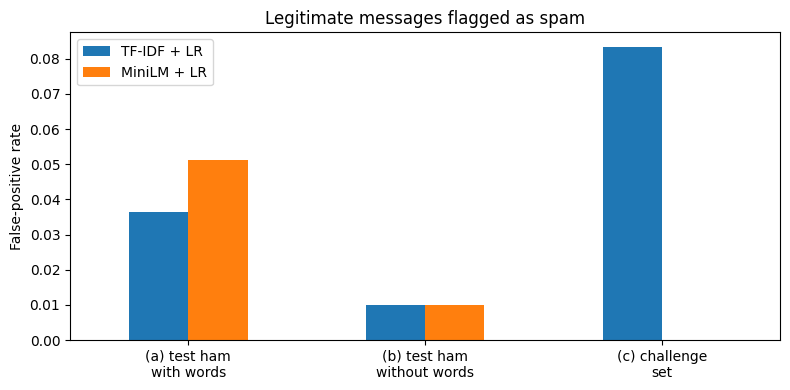

In [14]:
import matplotlib.pyplot as plt

fpr_cols = [c for c in results_df.columns if c.startswith("FPR")]
ax = results_df.loc[list(models), fpr_cols].T.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("False-positive rate"); ax.set_title("Legitimate messages flagged as spam")
ax.set_xticklabels(["(a) test ham\nwith words", "(b) test ham\nwithout words", "(c) challenge\nset"])
plt.tight_layout(); plt.savefig("results/fpr_chart.png", dpi=150); plt.show()

### 5.1 Error analysis
Wrong predictions on the test set for each method. For TF-IDF, `top_words` lists the words that pushed the message towards spam (coefficient × TF-IDF value). Each member explains at least three errors of their own method in the report.

In [15]:
tfidf_err = errors(tfidf_model, test)
tfidf_err["top_words"] = tfidf_err["text"].map(lambda t: tfidf_top_words(tfidf_model, t))
tfidf_err.to_csv("results/errors_tfidf.csv", index=False)
print("TF-IDF errors on test:", len(tfidf_err))
tfidf_err.head(10)

TF-IDF errors on test: 18


,text,label,pred,p_spam,top_words
0,"Did you hear about the new ""Divorce Barbie""? I...",1,0,0.102,"[(new, 0.542), (with, 0.364), (of, 0.08), (com..."
1,K..u also dont msg or reply to his msg..,0,1,0.846,"[(reply, 1.19), (msg, 1.084), (or, 0.74), (to,..."
2,Hello. We need some posh birds and chaps to us...,1,0,0.125,"[(your, 0.43), (to, 0.349), (for, 0.297), (use..."
3,Filthy stories and GIRLS waiting for your,1,0,0.425,"[(your, 0.83), (for, 0.573), (girls, 0.146), (..."
4,We have sent JD for Customer Service cum Accou...,0,1,0.792,"[(service, 0.643), (for, 0.545), (customer, 0...."
5,Host-based IDPS for linux systems.,0,1,0.722,"[(for, 2.873)]"
6,Would you like to see my XXX pics they are so ...,1,0,0.247,"[(uk, 0.741), (to, 0.349), (hot, 0.267), (xxx,..."
7,"Princess, is your kitty shaved or natural?",0,1,0.506,"[(or, 1.039), (your, 0.974), (is, 0.138), (is ..."
8,Dont you have message offer,0,1,0.643,"[(you have, 1.178), (dont you, 0.431), (messag..."
9,"Do you ever notice that when you're driving, a...",1,0,0.029,"[(is, 0.094), (is an, 0.075), (do you, 0.032),..."


In [16]:
emb_err = errors(emb_model, test)
emb_err.to_csv("results/errors_embedding.csv", index=False)
print("Embedding errors on test:", len(emb_err))
emb_err.head(10)

Embedding errors on test: 16


,text,label,pred,p_spam
0,"Did you hear about the new ""Divorce Barbie""? I...",1,0,0.041
1,Surely result will offer:),0,1,0.670
2,Hello. We need some posh birds and chaps to us...,1,0,0.377
3,Filthy stories and GIRLS waiting for your,1,0,0.319
4,I wonder if you'll get this text?,0,1,0.768
5,Fffff. Can you text kadeem or are you too far ...,0,1,0.656
6,"Argh my 3g is spotty, anyway the only thing I ...",0,1,0.560
7,Dont you have message offer,0,1,0.751
8,"Do you ever notice that when you're driving, a...",1,0,0.003
9,I've sent my wife your text. After we buy them...,0,1,0.656


In [17]:
# False alarms on legitimate messages that contain spam-associated words: where do the methods disagree?
pool = pd.concat([ham_with[["text", "label"]].assign(source="test ham (a)"),
                  challenge[["text", "label"]].assign(source="challenge (c)")], ignore_index=True)
side = predictions_side_by_side(models, pool[["text", "label"]]).assign(source=pool["source"])
disagree = side[side["TF-IDF + LR"] != side["MiniLM + LR"]]
disagree.to_csv("results/disagreements.csv", index=False)
print("Disagreements:", len(disagree))
disagree.head(10)

Disagreements: 15


,text,label,TF-IDF + LR,TF-IDF + LR P(spam),MiniLM + LR,MiniLM + LR P(spam),source
16,K..u also dont msg or reply to his msg..,0,1,0.846,0,0.002,test ham (a)
31,I wonder if you'll get this text?,0,0,0.223,1,0.768,test ham (a)
42,Fffff. Can you text kadeem or are you too far ...,0,0,0.175,1,0.656,test ham (a)
46,"Argh my 3g is spotty, anyway the only thing I ...",0,0,0.103,1,0.560,test ham (a)
68,Can... I'm free...,0,1,0.739,0,0.001,test ham (a)
78,I've sent my wife your text. After we buy them...,0,0,0.082,1,0.656,test ham (a)
82,"Hello, hello, hi lou sorry it took so long 2 r...",0,0,0.098,1,0.789,test ham (a)
84,Please protect yourself from e-threats. SIB ne...,0,1,0.617,0,0.061,test ham (a)
85,Let's pool our money together and buy a bunch ...,0,0,0.059,1,0.508,test ham (a)
99,U can call now...,0,1,0.589,0,0.005,test ham (a)


### 5.2 Original labelled examples (shown separately from test scores)

In [18]:
originals = pd.read_csv("data/original_examples.csv")
if len(originals):
    display(predictions_side_by_side(models, originals).assign(author=originals["author"]))
else:
    print("data/original_examples.csv is empty; each member adds two labelled examples.")

,text,label,TF-IDF + LR,TF-IDF + LR P(spam),MiniLM + LR,MiniLM + LR P(spam),author
0,The library is open until ten tonight; call me...,0,0,0.084,0,0.071,Faisal
1,You have been selected for an exclusive cash r...,1,1,0.985,1,0.997,Faisal
2,Can you send our group the final slide order b...,0,0,0.270,0,0.005,Saad
3,Congratulations! Your number was chosen for a ...,1,1,0.803,1,0.895,Saad
4,The new lab timetable is posted on the course ...,0,0,0.205,0,0.005,Nawaf
5,Limited-time offer: get a bonus voucher when y...,1,0,0.224,1,0.922,Nawaf


## 6. Try it
*Owner: Nawaf.* Loads the **saved** models (no retraining) and classifies a new message with both methods. Empty input returns a helpful message.

In [19]:
from src.predict import load_models, classify

saved_models = load_models()

message = "Are you free tomorrow? Call me after class"  # @param {type:"string"}
print(classify(message, saved_models))
print()
print(classify("   ", saved_models))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Message: "Are you free tomorrow? Call me after class"
  TF-IDF + LR  -> Not Spam (P(spam) = 0.22)
  MiniLM + LR  -> Not Spam (P(spam) = 0.00)

Please type a message to classify (the input was empty).


## 7. Sources
- Dataset: T. A. Almeida, J. M. G. Hidalgo, A. Yamakami, ACM DocEng 2011 — https://archive.ics.uci.edu/dataset/228/sms+spam+collection
- N. Reimers, I. Gurevych, Sentence-BERT, EMNLP-IJCNLP 2019 — pretrained weights `sentence-transformers/all-MiniLM-L6-v2`
- M. T. Ribeiro et al., CheckList, ACL 2020 — motivation for the challenge set
- Libraries: scikit-learn, pandas, numpy, sentence-transformers, joblib
- AI assistance: Claude (Anthropic) assisted with code structure and implementation, and with drafting the report, slides and appendix. ChatGPT (OpenAI) assisted with drafting the challenge-set messages, labelled examples and contribution-documentation templates. Each member was assigned one part of the system (data, Method 1, Method 2) and is responsible for reviewing, validating and explaining that part. The team is responsible for the submitted work.